<a href="https://colab.research.google.com/github/carolinaaraujo-cap/C-lculo-Num-rico/blob/main/Atividade_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Importa a biblioteca de funções matemáticas da linguagem Python.
import math

# Importa a biblioteca NumPy e cria o apelido convencional np.
import numpy as np

# Importa o módulo de gráficos pyplot e cria o apelido plt.
import matplotlib.pyplot as plt
import pandas as pd

# Define um estilo visual claro para todos os gráficos do notebook.
plt.style.use("seaborn-v0_8-whitegrid")

Se x é o valor de referência e x ̃︁ é uma aproximação, use

Ea = |x − x ̃︁| erro absoluto, (1)
Er =
|x − x ̃︁|
|x|

erro relativo, (2)
E% = 100Er erro percentual. (3)

Para n casas decimais:
• arredondamento: considera o primeiro algarismo descartado;
• truncamento: simplesmente elimina os algarismos posteriores à casa escolhida.
No Python, round(x,n) pode ser usado para arredondar. Para truncar sem arredondar,
implemente

xtrunc =
trunc(10nx)
10n
.


Valor original de x1: 3.14159265

Para 0 casas decimais:
  Arredondado: 3.0
    Erro absoluto:   0.1415926500
    Erro relativo:   4.507034e-02
    Erro percentual: 4.507034%
  Truncado: 3.0
    Erro absoluto:   0.1415926500
    Erro relativo:   4.507034e-02
    Erro percentual: 4.507034%

Para 1 casas decimais:
  Arredondado: 3.1
    Erro absoluto:   0.0415926500
    Erro relativo:   1.323935e-02
    Erro percentual: 1.323935%
  Truncado: 3.1
    Erro absoluto:   0.0415926500
    Erro relativo:   1.323935e-02
    Erro percentual: 1.323935%

Para 2 casas decimais:
  Arredondado: 3.14
    Erro absoluto:   0.0015926500
    Erro relativo:   5.069562e-04
    Erro percentual: 0.050696%
  Truncado: 3.14
    Erro absoluto:   0.0015926500
    Erro relativo:   5.069562e-04
    Erro percentual: 0.050696%

Para 3 casas decimais:
  Arredondado: 3.142
    Erro absoluto:   0.0004073500
    Erro relativo:   1.296635e-04
    Erro percentual: 0.012966%
  Truncado: 3.141
    Erro absoluto:   0.00059265

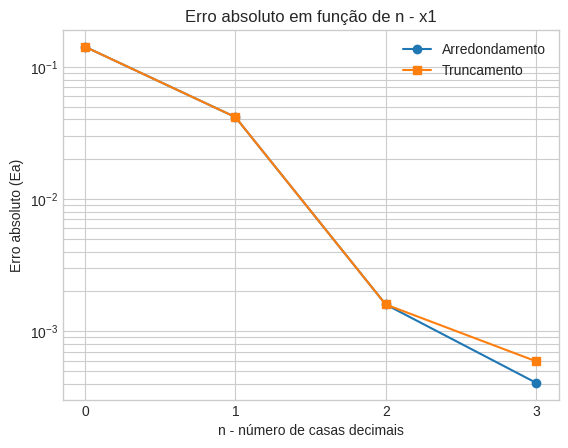

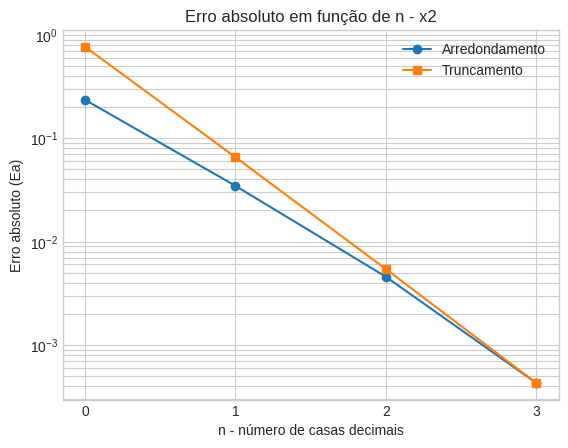

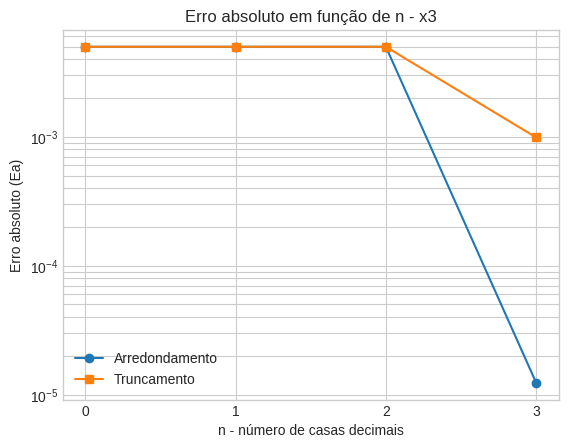

In [4]:


# Valores de referência
x1 = 3.14159265
x2 = 98.76543
x3 = 0.00498765


# ==========================================================
# FUNÇÃO PARA TRUNCAMENTO
# ==========================================================

# Define a função para truncar um número em determinada
# quantidade de casas decimais.
def truncar(value, num_decimals):

    # Calcula o fator que desloca a vírgula decimal.
    fator = 10 ** num_decimals

    # Trunca o número deslocado e devolve a vírgula
    # à posição original.
    return math.trunc(value * fator) / fator


# ==========================================================
# FUNÇÃO PARA CÁLCULO DOS ERROS
# ==========================================================

def calcular_erros(valor_referencia, valor_aproximado):

    # Calcula a distância entre o valor de referência
    # e a aproximação.
    erro_absoluto = abs(valor_referencia - valor_aproximado)

    # Divide o erro absoluto pelo módulo do valor de referência.
    erro_relativo = erro_absoluto / abs(valor_referencia)

    # Converte o erro relativo em porcentagem.
    erro_percentual = 100.0 * erro_relativo

    return erro_absoluto, erro_relativo, erro_percentual


# ==========================================================
# VALORES QUE SERÃO PROCESSADOS
# ==========================================================

numbers_to_process = {
    "x1": x1,
    "x2": x2,
    "x3": x3
}


# Lista para armazenar os resultados
resultados = []


# ==========================================================
# ARREDONDAMENTO E TRUNCAMENTO
# ==========================================================

for name, value in numbers_to_process.items():

    print(f"\nValor original de {name}: {value}")

    for n in range(0, 4):

        print(f"\nPara {n} casas decimais:")


        # --------------------------------------------------
        # ARREDONDAMENTO
        # --------------------------------------------------

        arredondado = round(value, n)

        Ea, Er, Epercentual = calcular_erros(
            value,
            arredondado
        )

        print(f"  Arredondado: {arredondado}")

        # Exibe o erro absoluto com dez casas decimais.
        print(f"    Erro absoluto:   {Ea:.10f}")

        # Exibe o erro relativo em notação científica.
        print(f"    Erro relativo:   {Er:.6e}")

        # Exibe o erro percentual com seis casas decimais.
        print(f"    Erro percentual: {Epercentual:.6f}%")

        resultados.append([
            name,
            value,
            n,
            "Arredondamento",
            arredondado,
            Ea,
            Er,
            Epercentual
        ])


        # --------------------------------------------------
        # TRUNCAMENTO
        # --------------------------------------------------

        truncado = truncar(value, n)

        Ea, Er, Epercentual = calcular_erros(
            value,
            truncado
        )

        print(f"  Truncado: {truncado}")

        # Exibe o erro absoluto com dez casas decimais.
        print(f"    Erro absoluto:   {Ea:.10f}")

        # Exibe o erro relativo em notação científica.
        print(f"    Erro relativo:   {Er:.6e}")

        # Exibe o erro percentual com seis casas decimais.
        print(f"    Erro percentual: {Epercentual:.6f}%")

        resultados.append([
            name,
            value,
            n,
            "Truncamento",
            truncado,
            Ea,
            Er,
            Epercentual
        ])


# ==========================================================
# 3. ORGANIZA OS RESULTADOS EM UMA TABELA
# ==========================================================

tabela = pd.DataFrame(
    resultados,
    columns=[
        "Número",
        "Valor de referência",
        "n",
        "Método",
        "Valor aproximado",
        "Ea",
        "Er",
        "E%"
    ]
)

print("\n")
print("=" * 80)
print("TABELA DE RESULTADOS")
print("=" * 80)

print(tabela.to_string(index=False))


# ==========================================================
# 4. GRÁFICO DE Ea EM FUNÇÃO DE n
# ==========================================================

for name in numbers_to_process:

    # Seleciona apenas os dados do número atual
    dados = tabela[tabela["Número"] == name]

    # Separa arredondamento e truncamento
    arred = dados[dados["Método"] == "Arredondamento"]
    trunc = dados[dados["Método"] == "Truncamento"]


    # Cria uma nova figura
    plt.figure()


    # Erro do arredondamento
    plt.semilogy(
        arred["n"],
        arred["Ea"],
        marker="o",
        label="Arredondamento"
    )


    # Erro do truncamento
    plt.semilogy(
        trunc["n"],
        trunc["Ea"],
        marker="s",
        label="Truncamento"
    )


    # Nome dos eixos
    plt.xlabel("n - número de casas decimais")
    plt.ylabel("Erro absoluto (Ea)")


    # Título
    plt.title(
        f"Erro absoluto em função de n - {name}"
    )


    # Define os valores mostrados no eixo x
    plt.xticks(range(0, 4))


    # Grade
    plt.grid(
        True,
        which="both"
    )


    # Legenda
    plt.legend()


    # Mostra o gráfico
    plt.show()

**5. responda: arredondar sempre gera erro menor ou igual ao truncamento? Justifique com os resultados.**
Como demonstram os resultados acima, a técnica de arredondamento gera erros menores ou iguais aos do truncamento, isto porque leva em consideração a casa decimal seguinte.

Parte B – medidas de pressão arterial
Um equipamento registrou dez medidas consecutivas de pressão arterial sistólica, em mmHg:

121,7; 120,4; 122,1; 119,8; 121,2; 120,9; 122,4; 121,0; 120,2; 121,5.
Considere como referência a média calculada com todos os algarismos disponíveis.
B.1 Representação das medidas
Crie quatro séries:
1. dados originais;
2. dados arredondados para o inteiro mais próximo;
3. dados truncados para números inteiros.
Para cada série, determine média, mínimo, máximo, amplitude e desvio-padrão amostral.
Calcule os três erros da média aproximada em relação à média de referência.
B.2 Gráficos obrigatórios
Produza:
1. gráfico das dez medições, mostrando as quatro séries;
2. gráfico de barras dos erros absolutos das médias;
3. gráfico de barras dos erros percentuais das médias;
4. histograma dos dados originais e dos dados inteiros arredondados.
Explique se a representação inteira é suficiente para preservar a média e a variabilidade
desta pequena amostra. Não faça interpretação médica dos valores.

Média dos dados originais: 121.12
Dados originais: [121.7, 120.4, 122.1, 119.8, 121.2, 120.9, 122.4, 121.0, 120.2, 121.5]
Dados arredondados: [122.0, 120.0, 122.0, 120.0, 121.0, 121.0, 122.0, 121.0, 120.0, 122.0]
Dados truncados: [121.0, 120.0, 122.0, 119.0, 121.0, 120.0, 122.0, 121.0, 120.0, 121.0]
Média dos dados arredondados: 121.1
Média dos dados truncados: 120.7
Mínimo dos dados originais: 119.8
Máximo dos dados originais: 122.4
Mínimo dos dados arredondados: 120.0
Máximo dos dados arredondados: 122.0
Mínimo dos dados truncados: 119.0
Máximo dos dados truncados: 122.0
Desvio padrão dos dados originais: 0.7909487973314074
Desvio padrão dos dados arredondados: 0.8306623862918074
Desvio padrão dos dados truncados: 0.9

ERROS DA MÉDIA ARREDONDADA
Erro absoluto:   0.0200000000
Erro relativo:   1.651255e-04
Erro percentual: 0.016513%

ERROS DA MÉDIA TRUNCADA
Erro absoluto:   0.4200000000
Erro relativo:   3.467635e-03
Erro percentual: 0.346764%


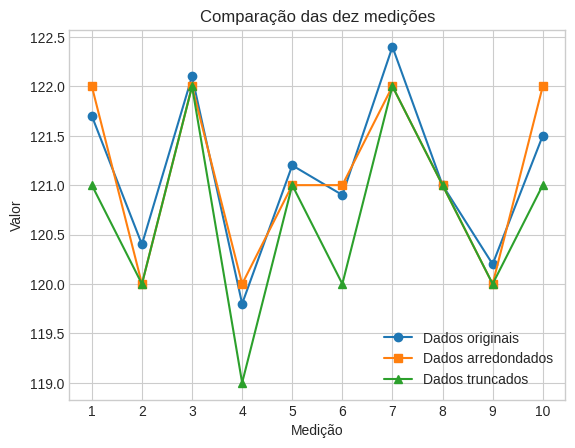

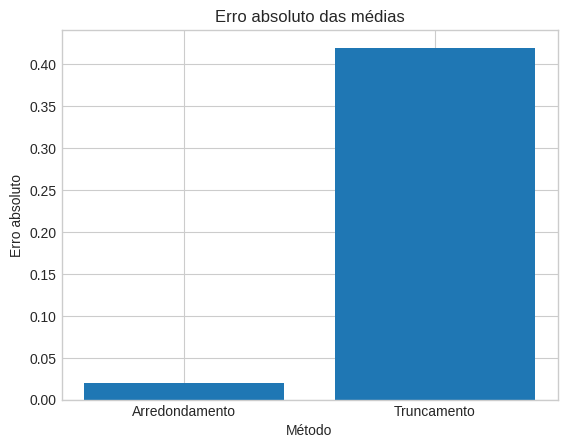

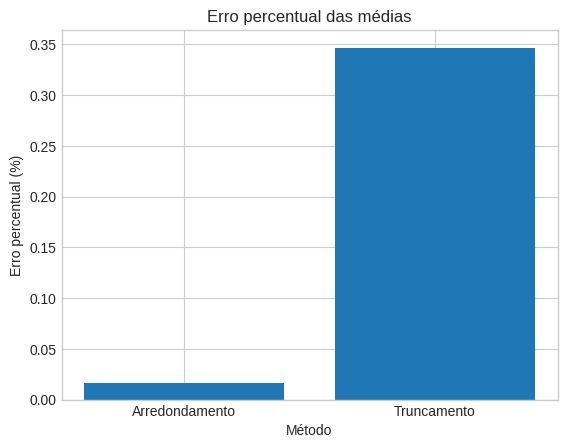

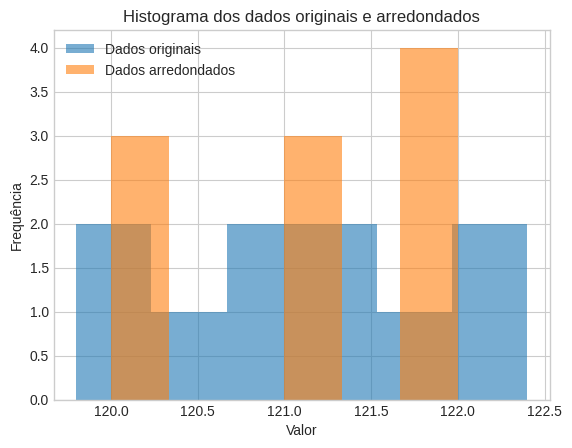

In [5]:
# ==========================================================
# DADOS ORIGINAIS
# ==========================================================

import statistics

p = [
    121.7, 120.4, 122.1, 119.8, 121.2,
    120.9, 122.4, 121.0, 120.2, 121.5
]


# ==========================================================
# MÉDIA DOS DADOS ORIGINAIS
# ==========================================================

media = sum(p) / len(p)

print(f"Média dos dados originais: {media}")

Valorderef = media

print(f"Dados originais: {p}")


# ==========================================================
# ARREDONDAMENTO E TRUNCAMENTO
# ==========================================================

# Dados arredondados para o inteiro mais próximo
a = [round(x, 0) for x in p]

# Dados truncados para números inteiros
t = [truncar(x, 0) for x in p]

print(f"Dados arredondados: {a}")
print(f"Dados truncados: {t}")


# ==========================================================
# MÉDIAS
# ==========================================================

mediaa = sum(a) / len(a)
mediat = sum(t) / len(t)

print(f"Média dos dados arredondados: {mediaa}")
print(f"Média dos dados truncados: {mediat}")


# ==========================================================
# MÍNIMOS E MÁXIMOS
# ==========================================================

minp = min(p)
maxp = max(p)

print(f"Mínimo dos dados originais: {minp}")
print(f"Máximo dos dados originais: {maxp}")


mina = min(a)
maxa = max(a)

print(f"Mínimo dos dados arredondados: {mina}")
print(f"Máximo dos dados arredondados: {maxa}")


mint = min(t)
maxt = max(t)

print(f"Mínimo dos dados truncados: {mint}")
print(f"Máximo dos dados truncados: {maxt}")


# ==========================================================
# DESVIO PADRÃO
# ==========================================================

desvp = statistics.pstdev(p)
desva = statistics.pstdev(a)
desvt = statistics.pstdev(t)

print(f"Desvio padrão dos dados originais: {desvp}")
print(f"Desvio padrão dos dados arredondados: {desva}")
print(f"Desvio padrão dos dados truncados: {desvt}")


# ==========================================================
# ERROS DAS MÉDIAS
# ==========================================================

# Erro da média arredondada
Ea_a, Er_a, Eperc_a = calcular_erros(
    Valorderef,
    mediaa
)

# Erro da média truncada
Ea_t, Er_t, Eperc_t = calcular_erros(
    Valorderef,
    mediat
)


print("\nERROS DA MÉDIA ARREDONDADA")

print(f"Erro absoluto:   {Ea_a:.10f}")
print(f"Erro relativo:   {Er_a:.6e}")
print(f"Erro percentual: {Eperc_a:.6f}%")


print("\nERROS DA MÉDIA TRUNCADA")

print(f"Erro absoluto:   {Ea_t:.10f}")
print(f"Erro relativo:   {Er_t:.6e}")
print(f"Erro percentual: {Eperc_t:.6f}%")


# ==========================================================
# 1. GRÁFICO DAS DEZ MEDIÇÕES
# MOSTRANDO AS TRÊS SÉRIES
# ==========================================================

medicoes = range(1, len(p) + 1)

plt.figure()

plt.plot(
    medicoes,
    p,
    marker="o",
    label="Dados originais"
)

plt.plot(
    medicoes,
    a,
    marker="s",
    label="Dados arredondados"
)

plt.plot(
    medicoes,
    t,
    marker="^",
    label="Dados truncados"
)

plt.xlabel("Medição")
plt.ylabel("Valor")
plt.title("Comparação das dez medições")

plt.xticks(medicoes)

plt.grid(True)

plt.legend()

plt.show()


# ==========================================================
# 2. GRÁFICO DE BARRAS DOS ERROS ABSOLUTOS DAS MÉDIAS
# ==========================================================

metodos = [
    "Arredondamento",
    "Truncamento"
]

erros_absolutos = [
    Ea_a,
    Ea_t
]


plt.figure()

plt.bar(
    metodos,
    erros_absolutos
)

plt.xlabel("Método")
plt.ylabel("Erro absoluto")
plt.title("Erro absoluto das médias")

plt.show()


# ==========================================================
# 3. GRÁFICO DE BARRAS DOS ERROS PERCENTUAIS DAS MÉDIAS
# ==========================================================

erros_percentuais = [
    Eperc_a,
    Eperc_t
]


plt.figure()

plt.bar(
    metodos,
    erros_percentuais
)

plt.xlabel("Método")
plt.ylabel("Erro percentual (%)")
plt.title("Erro percentual das médias")

plt.show()


# ==========================================================
# 4. HISTOGRAMA DOS DADOS ORIGINAIS
# E DOS DADOS INTEIROS ARREDONDADOS
# ==========================================================

plt.figure()

plt.hist(
    p,
    bins=6,
    alpha=0.6,
    label="Dados originais"
)

plt.hist(
    a,
    bins=6,
    alpha=0.6,
    label="Dados arredondados"
)

plt.xlabel("Valor")
plt.ylabel("Frequência")
plt.title(
    "Histograma dos dados originais e arredondados"
)

plt.legend()

plt.show()

**Explique se a representação inteira é suficiente para preservar a média e a variabilidade desta pequena amostra. Não faça interpretação médica dos valores.**
Sim, pois não gerou grandes variações no desvio padrão ou grandes valores de erro quando comparada a média dos valores originais.

In [6]:
# ==========================================================
# FUNÇÃO PARA TRUNCAMENTO
# ==========================================================

def truncar(value, num_decimals):

    fator = 10 ** num_decimals

    return math.trunc(value * fator) / fator


# ==========================================================
# FUNÇÃO PARA TRUNCAR EM CENTENAS
# ==========================================================

def truncar_centenas(value):

    return math.trunc(value / 100) * 100


# ==========================================================
# FUNÇÃO PARA CÁLCULO DOS ERROS
# ==========================================================

def calcular_erros(valor_referencia, valor_aproximado):

    erro_absoluto = abs(
        valor_referencia - valor_aproximado
    )

    erro_relativo = (
        erro_absoluto / abs(valor_referencia)
    )

    erro_percentual = (
        100.0 * erro_relativo
    )

    return (
        erro_absoluto,
        erro_relativo,
        erro_percentual
    )


# ==========================================================
# FUNÇÃO HAGEN-POISEUILLE
# ==========================================================

def vazao(r, delta_p, mu, L):

    Q = (
        math.pi
        * r**4
        * delta_p
        / (8 * mu * L)
    )

    return Q


# ==========================================================
# VALORES DE REFERÊNCIA
# ==========================================================

r_mm = 0.80
r = r_mm * 1e-3

L = 0.20

mu = 3.5e-3

delta_p = 1200


# ==========================================================
# VAZÃO DE REFERÊNCIA
# ==========================================================

Q_ref = vazao(
    r,
    delta_p,
    mu,
    L
)


print(
    f"Vazão de referência: {Q_ref:.10e} m³/s"
)


# ==========================================================
# APROXIMAÇÕES DO RAIO
# ==========================================================

r_arred_mm = round(
    r_mm,
    1
)

r_trunc_mm = truncar(
    r_mm,
    1
)


r_arred = r_arred_mm * 1e-3
r_trunc = r_trunc_mm * 1e-3


# ==========================================================
# APROXIMAÇÕES DA VISCOSIDADE
# ==========================================================

mu_arred = round(
    mu,
    3
)

mu_trunc = truncar(
    mu,
    3
)


# ==========================================================
# APROXIMAÇÕES DA PRESSÃO
# ==========================================================

dp_arred = round(
    delta_p,
    -2
)

dp_trunc = truncar_centenas(
    delta_p
)


# ==========================================================
# CENÁRIOS
# ==========================================================

cenarios = {

    "Referência":
        (r, mu, delta_p),

    "r arredondado":
        (r_arred, mu, delta_p),

    "r truncado":
        (r_trunc, mu, delta_p),

    "mu arredondada":
        (r, mu_arred, delta_p),

    "mu truncada":
        (r, mu_trunc, delta_p),

    "Delta p arredondada":
        (r, mu, dp_arred),

    "Delta p truncada":
        (r, mu, dp_trunc),

    "Todas arredondadas":
        (
            r_arred,
            mu_arred,
            dp_arred
        ),

    "Todas truncadas":
        (
            r_trunc,
            mu_trunc,
            dp_trunc
        )
}


resultados = []


for nome, valores in cenarios.items():

    r_c, mu_c, dp_c = valores

    Q = vazao(
        r_c,
        dp_c,
        mu_c,
        L
    )


    Ea, Er, Eperc = calcular_erros(
        Q_ref,
        Q
    )


    resultados.append([
        nome,
        Q,
        Ea,
        Er,
        Eperc
    ])


# ==========================================================
# TABELA
# ==========================================================

tabela_C1 = pd.DataFrame(

    resultados,

    columns=[
        "Cenário",
        "Q (m³/s)",
        "Ea (m³/s)",
        "Er",
        "E%"
    ]
)


print(
    tabela_C1.to_string(index=False)
)

Vazão de referência: 2.7574207520e-07 m³/s
            Cenário     Q (m³/s)    Ea (m³/s)       Er        E%
         Referência 2.757421e-07 0.000000e+00 0.000000  0.000000
      r arredondado 2.757421e-07 0.000000e+00 0.000000  0.000000
         r truncado 2.757421e-07 0.000000e+00 0.000000  0.000000
     mu arredondada 2.412743e-07 3.446776e-08 0.125000 12.500000
        mu truncada 3.216991e-07 4.595701e-08 0.166667 16.666667
Delta p arredondada 2.757421e-07 0.000000e+00 0.000000  0.000000
   Delta p truncada 2.757421e-07 0.000000e+00 0.000000  0.000000
 Todas arredondadas 2.412743e-07 3.446776e-08 0.125000 12.500000
    Todas truncadas 3.216991e-07 4.595701e-08 0.166667 16.666667


C.2 Sensibilidade
Varie o raio de 0,70 a 0,90 mm. Para cada raio, compare Q de referência, Q após arredondar
o raio para uma casa decimal e Q após truncá-lo para uma casa decimal.
Faça os gráficos:
1. Q em função de r;
2. erro absoluto de Q em função de r;
3. erro relativo de Q em função de r;
4. erro percentual de Q em função de r.
Explique por que o erro no raio é amplificado na vazão. Relacione sua resposta ao expoente quatro

 r (mm)  Q referência  Q arredondado   Q truncado  Ea arredondamento  Ea truncamento  Er arredondamento  Er truncamento  E% arredondamento  E% truncamento
   0.70  1.616349e-07   1.616349e-07 1.616349e-07       0.000000e+00    0.000000e+00       0.000000e+00    0.000000e+00       0.000000e+00    0.000000e+00
   0.71  1.710710e-07   1.616349e-07 1.616349e-07       9.436094e-09    9.436094e-09       5.515892e-02    5.515892e-02       5.515892e+00    5.515892e+00
   0.72  1.809144e-07   1.616349e-07 1.616349e-07       1.927943e-08    1.927943e-08       1.065666e-01    1.065666e-01       1.065666e+01    1.065666e+01
   0.73  1.911765e-07   1.616349e-07 1.616349e-07       2.954157e-08    2.954157e-08       1.545251e-01    1.545251e-01       1.545251e+01    1.545251e+01
   0.74  2.018692e-07   1.616349e-07 1.616349e-07       4.023422e-08    4.023422e-08       1.993084e-01    1.993084e-01       1.993084e+01    1.993084e+01
   0.75  2.130042e-07   2.757421e-07 1.616349e-07       6.273789e-08  

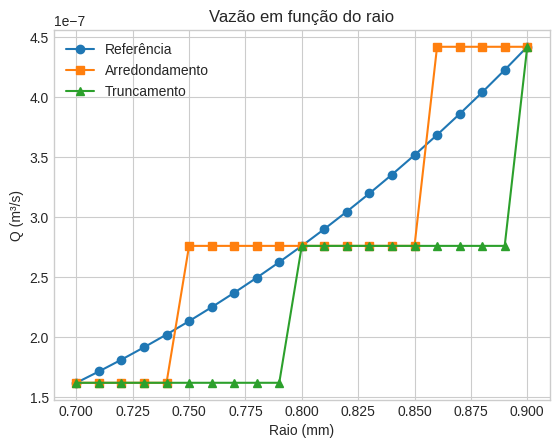

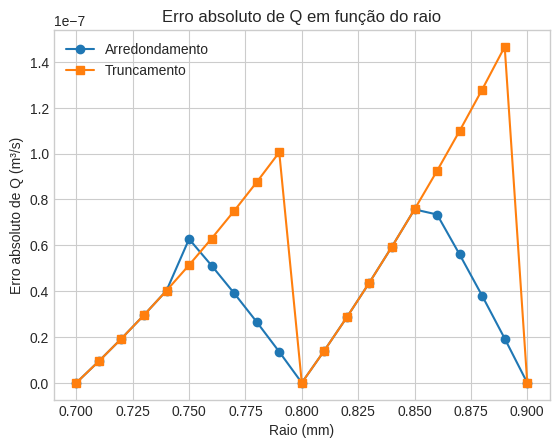

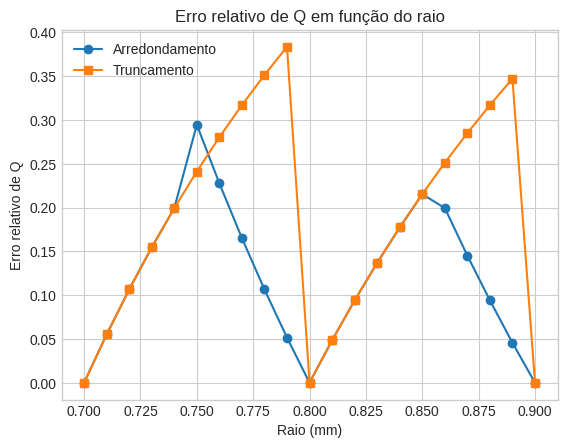

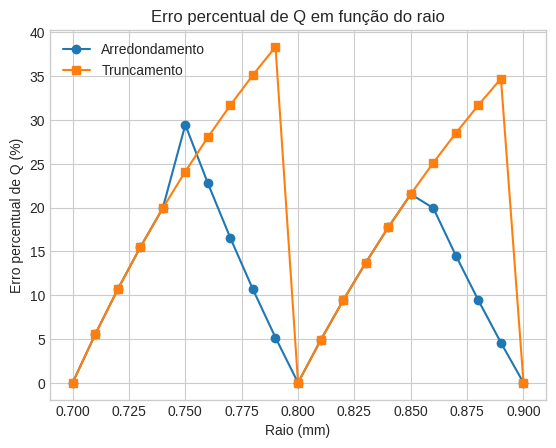

In [7]:
# ==========================================================
# CONSTANTES
# ==========================================================

L = 0.20
mu = 3.5e-3
delta_p = 1200


# Raios de 0,70 até 0,90 mm
raios_mm = np.arange(
    0.70,
    0.901,
    0.01
)


resultados = []


for r_mm in raios_mm:

    # Raio de referência em metros
    r_ref = r_mm * 1e-3


    # Arredondamento
    r_arred_mm = round(
        r_mm,
        1
    )


    # Truncamento
    r_trunc_mm = truncar(
        r_mm,
        1
    )


    # Conversão para metros
    r_arred = r_arred_mm * 1e-3
    r_trunc = r_trunc_mm * 1e-3


    # Vazões
    Q_ref = vazao(
        r_ref,
        delta_p,
        mu,
        L
    )

    Q_arred = vazao(
        r_arred,
        delta_p,
        mu,
        L
    )

    Q_trunc = vazao(
        r_trunc,
        delta_p,
        mu,
        L
    )


    # Erros arredondamento
    Ea_a, Er_a, Ep_a = calcular_erros(
        Q_ref,
        Q_arred
    )


    # Erros truncamento
    Ea_t, Er_t, Ep_t = calcular_erros(
        Q_ref,
        Q_trunc
    )


    resultados.append([
        r_mm,
        Q_ref,
        Q_arred,
        Q_trunc,
        Ea_a,
        Ea_t,
        Er_a,
        Er_t,
        Ep_a,
        Ep_t
    ])


# ==========================================================
# TABELA
# ==========================================================

tabela_C2 = pd.DataFrame(

    resultados,

    columns=[
        "r (mm)",
        "Q referência",
        "Q arredondado",
        "Q truncado",
        "Ea arredondamento",
        "Ea truncamento",
        "Er arredondamento",
        "Er truncamento",
        "E% arredondamento",
        "E% truncamento"
    ]
)


print(
    tabela_C2.to_string(index=False)
)
plt.figure()

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Q referência"],
    marker="o",
    label="Referência"
)

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Q arredondado"],
    marker="s",
    label="Arredondamento"
)

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Q truncado"],
    marker="^",
    label="Truncamento"
)

plt.xlabel("Raio (mm)")
plt.ylabel("Q (m³/s)")

plt.title(
    "Vazão em função do raio"
)

plt.grid(True)
plt.legend()

plt.show()
plt.figure()

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Ea arredondamento"],
    marker="o",
    label="Arredondamento"
)

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Ea truncamento"],
    marker="s",
    label="Truncamento"
)

plt.xlabel("Raio (mm)")
plt.ylabel("Erro absoluto de Q (m³/s)")

plt.title(
    "Erro absoluto de Q em função do raio"
)

plt.grid(True)
plt.legend()

plt.show()
plt.figure()

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Er arredondamento"],
    marker="o",
    label="Arredondamento"
)

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Er truncamento"],
    marker="s",
    label="Truncamento"
)

plt.xlabel("Raio (mm)")
plt.ylabel("Erro relativo de Q")

plt.title(
    "Erro relativo de Q em função do raio"
)

plt.grid(True)
plt.legend()

plt.show()
plt.figure()

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["E% arredondamento"],
    marker="o",
    label="Arredondamento"
)

plt.plot(
    tabela_C2["r (mm)"],
    tabela_C2["E% truncamento"],
    marker="s",
    label="Truncamento"
)

plt.xlabel("Raio (mm)")
plt.ylabel("Erro percentual de Q (%)")

plt.title(
    "Erro percentual de Q em função do raio"
)

plt.grid(True)
plt.legend()

plt.show()

**Explique por que o erro no raio é amplificado na vazão. Relacione sua resposta ao expoente quatro.**
Isso é porque o expoente 4, aumenta a influência do raio na vazão, o que automaticamente tem o mesmo efeito no erro.

Considere um modelo didático de nanocateter cilíndrico:
r = 50 nm, L = 10 µm, µ = 3,5 × 10−3 Pa s, ∆p = 5000 Pa.
Use novamente Hagen–Poiseuille para calcular Q.
D.1 Erro geométrico
Considere erros no raio de ∆r = 0,1; 0,2; . . . ; 5,0 nm. Para cada valor, calcule
r− = r − ∆r, r+ = r + ∆r,
e as vazões correspondentes. Calcule os erros máximo absoluto, relativo e percentual em
relação a Q(r).
Construa:
1. gráfico de Q(r−), Q(r) e Q(r+);
2. gráfico do erro absoluto máximo de Q;
3. gráfico do erro relativo máximo de Q;
4. gráfico do erro percentual máximo de Q.
Compare o erro direto com a aproximação linear
∆Q
Q
≈ 4
∆r
r
.

Q de referência = 3.5062418009e-19 m³/s
 Δr (nm)        Q(r-)         Q(r)        Q(r+)    Ea máximo  Er máximo  E% máximo  4Δr/r
     0.1 3.478276e-19 3.506242e-19 3.534376e-19 2.813420e-21   0.008024   0.802403  0.008
     0.2 3.450478e-19 3.506242e-19 3.562679e-19 5.643737e-21   0.016096   1.609626  0.016
     0.3 3.422846e-19 3.506242e-19 3.591152e-19 8.491019e-21   0.024217   2.421687  0.024
     0.4 3.395381e-19 3.506242e-19 3.619795e-19 1.135533e-20   0.032386   3.238605  0.032
     0.5 3.368082e-19 3.506242e-19 3.648609e-19 1.423675e-20   0.040604   4.060401  0.040
     0.6 3.340947e-19 3.506242e-19 3.677595e-19 1.713533e-20   0.048871   4.887093  0.048
     0.7 3.313977e-19 3.506242e-19 3.706753e-19 2.005115e-20   0.057187   5.718701  0.056
     0.8 3.287171e-19 3.506242e-19 3.736085e-19 2.298427e-20   0.065552   6.555245  0.064
     0.9 3.260527e-19 3.506242e-19 3.765590e-19 2.593477e-20   0.073967   7.396743  0.072
     1.0 3.234046e-19 3.506242e-19 3.795269e-19 2.890271e-20

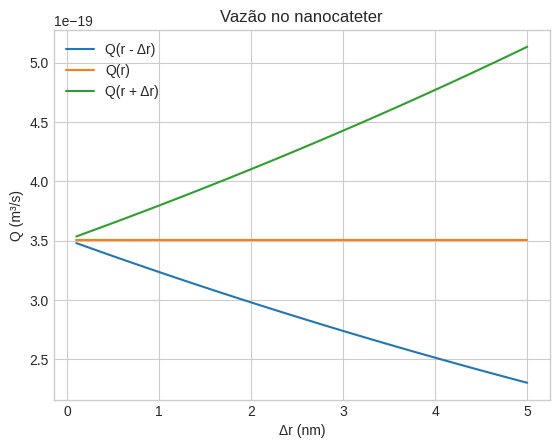

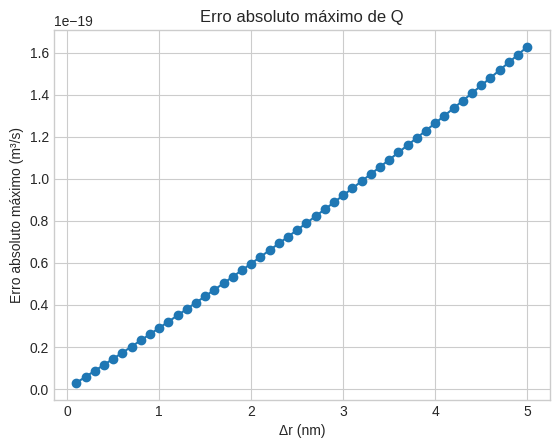

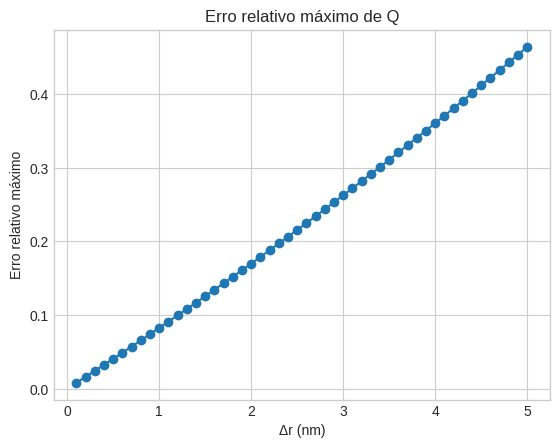

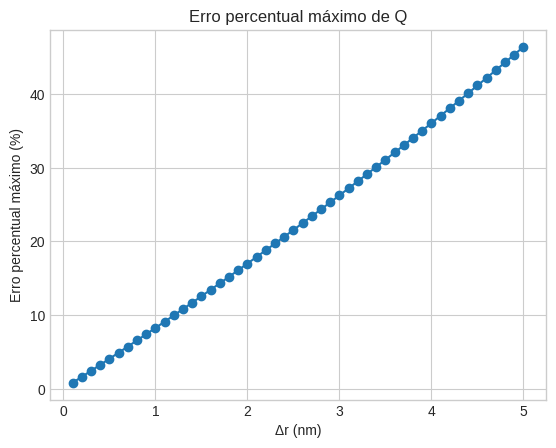

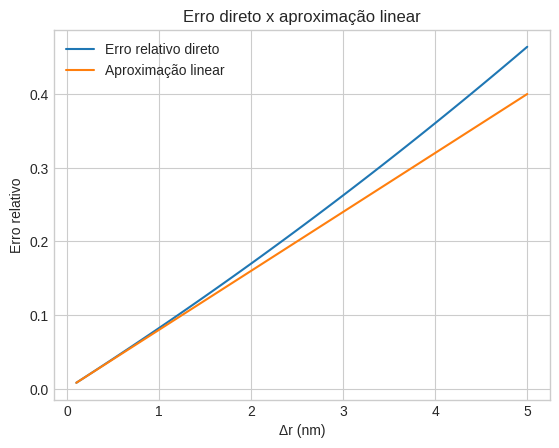

In [8]:
# ==========================================================
# VALORES DO NANOCATETER
# ==========================================================

r_nm = 50
r = r_nm * 1e-9

L = 10e-6

mu = 3.5e-3

delta_p = 5000


# ==========================================================
# VAZÃO DE REFERÊNCIA
# ==========================================================

Q_ref = vazao(
    r,
    delta_p,
    mu,
    L
)


print(
    f"Q de referência = {Q_ref:.10e} m³/s"
)


# ==========================================================
# VARIAÇÕES DO RAIO
# ==========================================================

delta_r_nm = np.arange(
    0.1,
    5.01,
    0.1
)


resultados = []


for dr_nm in delta_r_nm:

    dr = dr_nm * 1e-9


    r_menos = r - dr
    r_mais = r + dr


    Q_menos = vazao(
        r_menos,
        delta_p,
        mu,
        L
    )


    Q_mais = vazao(
        r_mais,
        delta_p,
        mu,
        L
    )


    # Erros das duas situações
    Ea_menos, Er_menos, Ep_menos = calcular_erros(
        Q_ref,
        Q_menos
    )

    Ea_mais, Er_mais, Ep_mais = calcular_erros(
        Q_ref,
        Q_mais
    )


    # Maior erro observado
    Ea_max = max(
        Ea_menos,
        Ea_mais
    )

    Er_max = max(
        Er_menos,
        Er_mais
    )

    Ep_max = max(
        Ep_menos,
        Ep_mais
    )


    # Aproximação linear
    aproximacao_linear = (
        4 * dr / r
    )


    resultados.append([
        dr_nm,
        Q_menos,
        Q_ref,
        Q_mais,
        Ea_max,
        Er_max,
        Ep_max,
        aproximacao_linear
    ])


# ==========================================================
# TABELA
# ==========================================================

tabela_D1 = pd.DataFrame(

    resultados,

    columns=[
        "Δr (nm)",
        "Q(r-)",
        "Q(r)",
        "Q(r+)",
        "Ea máximo",
        "Er máximo",
        "E% máximo",
        "4Δr/r"
    ]
)


print(
    tabela_D1.to_string(index=False)
)
plt.figure()

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["Q(r-)"],
    label="Q(r - Δr)"
)

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["Q(r)"],
    label="Q(r)"
)

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["Q(r+)"],
    label="Q(r + Δr)"
)

plt.xlabel("Δr (nm)")
plt.ylabel("Q (m³/s)")

plt.title(
    "Vazão no nanocateter"
)

plt.grid(True)
plt.legend()

plt.show()
plt.figure()

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["Ea máximo"],
    marker="o"
)

plt.xlabel("Δr (nm)")
plt.ylabel("Erro absoluto máximo (m³/s)")

plt.title(
    "Erro absoluto máximo de Q"
)

plt.grid(True)

plt.show()
plt.figure()

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["Er máximo"],
    marker="o"
)

plt.xlabel("Δr (nm)")
plt.ylabel("Erro relativo máximo")

plt.title(
    "Erro relativo máximo de Q"
)

plt.grid(True)

plt.show()
plt.figure()

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["E% máximo"],
    marker="o"
)

plt.xlabel("Δr (nm)")
plt.ylabel("Erro percentual máximo (%)")

plt.title(
    "Erro percentual máximo de Q"
)

plt.grid(True)

plt.show()
plt.figure()

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["Er máximo"],
    label="Erro relativo direto"
)

plt.plot(
    tabela_D1["Δr (nm)"],
    tabela_D1["4Δr/r"],
    label="Aproximação linear"
)

plt.xlabel("Δr (nm)")
plt.ylabel("Erro relativo")

plt.title(
    "Erro direto x aproximação linear"
)

plt.grid(True)
plt.legend()

plt.show()

D.2 Precisão computacional
Repita o cálculo de Q usando numpy.float32 e numpy.float64. Registre:
• r
4
em cada precisão;
• Q em cada precisão;
• diferença absoluta e relativa entre os resultados;
• np.finfo(...).eps de cada tipo.
Depois calcule uma pequena variação de vazão de duas formas:
δ1 =
Q(r + ∆r) − Q(r)
Q(r)
, (6)
δ2 =
(︃
1 +
∆r
r
)︃4
− 1. (7)
Compare as duas expressões para valores progressivamente menores de ∆r/r e identifique
possível perda de significância por cancelamento.

r⁴ float32 = 6.2500003960e-30
r⁴ float64 = 6.2500000000e-30
Q float32 = 3.5062423237e-19
Q float64 = 3.5062418009e-19
Diferença absoluta = 5.2286276892e-26
Diferença relativa = 1.4912342006e-07
Epsilon float32 = 1.1920928955e-07
Epsilon float64 = 2.2204460493e-16
        Δr/r           δ1           δ2    |δ1 - δ2|
1.000000e-01 4.641000e-01 4.641000e-01 8.326673e-16
1.000000e-02 4.060401e-02 4.060401e-02 3.608225e-16
1.000000e-03 4.006004e-03 4.006004e-03 2.237793e-16
1.000000e-04 4.000600e-04 4.000600e-04 1.295622e-17
1.000000e-05 4.000060e-05 4.000060e-05 5.011657e-16
1.000000e-06 4.000006e-06 4.000006e-06 2.611174e-16
1.000000e-07 4.000001e-07 4.000001e-07 4.612785e-16
1.000000e-08 4.000000e-08 4.000000e-08 1.801244e-16
1.000000e-09 4.000000e-09 4.000000e-09 6.414137e-16
1.000000e-10 4.000000e-10 4.000000e-10 4.519397e-18
1.000000e-11 3.999984e-11 4.000000e-11 1.643339e-16
1.000000e-12 4.000039e-12 4.000356e-12 3.167761e-16


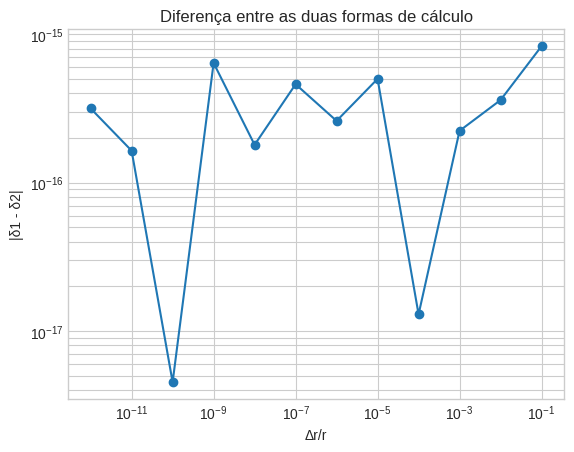

In [9]:
# ==========================================================
# VALORES
# ==========================================================

r32 = np.float32(50e-9)
r64 = np.float64(50e-9)

L32 = np.float32(10e-6)
L64 = np.float64(10e-6)

mu32 = np.float32(3.5e-3)
mu64 = np.float64(3.5e-3)

dp32 = np.float32(5000)
dp64 = np.float64(5000)


# ==========================================================
# r⁴
# ==========================================================

r4_32 = r32 ** np.float32(4)
r4_64 = r64 ** np.float64(4)


# ==========================================================
# VAZÃO FLOAT32
# ==========================================================

Q32 = (
    np.float32(np.pi)
    * r4_32
    * dp32
    / (
        np.float32(8)
        * mu32
        * L32
    )
)


# ==========================================================
# VAZÃO FLOAT64
# ==========================================================

Q64 = (
    np.float64(np.pi)
    * r4_64
    * dp64
    / (
        np.float64(8)
        * mu64
        * L64
    )
)


# ==========================================================
# DIFERENÇAS
# ==========================================================

diferenca_absoluta = abs(
    np.float64(Q64)
    - np.float64(Q32)
)


diferenca_relativa = (
    diferenca_absoluta
    / abs(np.float64(Q64))
)


# ==========================================================
# EPSILON
# ==========================================================

eps32 = np.finfo(
    np.float32
).eps

eps64 = np.finfo(
    np.float64
).eps


# ==========================================================
# RESULTADOS
# ==========================================================

print(
    f"r⁴ float32 = {r4_32:.10e}"
)

print(
    f"r⁴ float64 = {r4_64:.10e}"
)

print(
    f"Q float32 = {Q32:.10e}"
)

print(
    f"Q float64 = {Q64:.10e}"
)

print(
    f"Diferença absoluta = {diferenca_absoluta:.10e}"
)

print(
    f"Diferença relativa = {diferenca_relativa:.10e}"
)

print(
    f"Epsilon float32 = {eps32:.10e}"
)

print(
    f"Epsilon float64 = {eps64:.10e}"
)
# ==========================================================
# FUNÇÃO Q
# ==========================================================

def vazao_numpy(r, delta_p, mu, L):

    return (
        np.pi
        * r**4
        * delta_p
        / (8 * mu * L)
    )

# ==========================================================
# CONSTANTES
# ==========================================================

r = np.float64(
    50e-9
)

L = np.float64(
    10e-6
)

mu = np.float64(
    3.5e-3
)

delta_p = np.float64(
    5000
)


Q_r = vazao_numpy(
    r,
    delta_p,
    mu,
    L
)


# ==========================================================
# VALORES PROGRESSIVAMENTE MENORES DE Δr/r
# ==========================================================

razoes = [
    1e-1,
    1e-2,
    1e-3,
    1e-4,
    1e-5,
    1e-6,
    1e-7,
    1e-8,
    1e-9,
    1e-10,
    1e-11,
    1e-12
]


resultados = []


for razao in razoes:

    delta_r = (
        razao * r
    )


    # ------------------------------------------------------
    # FORMA 1
    # ------------------------------------------------------

    Q_novo = vazao_numpy(
        r + delta_r,
        delta_p,
        mu,
        L
    )


    delta1 = (
        (Q_novo - Q_r)
        / Q_r
    )


    # ------------------------------------------------------
    # FORMA 2
    # ------------------------------------------------------

    delta2 = (
        (1 + delta_r / r)**4
        - 1
    )


    diferenca = abs(
        delta1 - delta2
    )


    resultados.append([
        razao,
        delta1,
        delta2,
        diferenca
    ])


# ==========================================================
# TABELA
# ==========================================================

tabela_D2 = pd.DataFrame(

    resultados,

    columns=[
        "Δr/r",
        "δ1",
        "δ2",
        "|δ1 - δ2|"
    ]
)


print(
    tabela_D2.to_string(index=False)
)
plt.figure()

plt.loglog(
    tabela_D2["Δr/r"],
    tabela_D2["|δ1 - δ2|"],
    marker="o"
)

plt.xlabel("Δr/r")

plt.ylabel(
    "|δ1 - δ2|"
)

plt.title(
    "Diferença entre as duas formas de cálculo"
)

plt.grid(
    True,
    which="both"
)

plt.show()

**Compare as duas expressões para valores progressivamente menores de ∆r/r e identifique
possível perda de significância por cancelamento.**
Quanto menor a diferença de Delta r/r, maior a chance de cancelamento, pois a diferença entre os dois metodos fica nas menores casas decimais, o que gera uma perda de significância por cancelamento


**D.3 Fenômeno físico
Explique, em um parágrafo, que a redução da escala aumenta a razão superfície/volume e
torna os efeitos viscosos e de parede mais importantes.
Um resultado com muitas casas decimais pode ser numericamente preciso e, ainda
assim, fisicamente inadequado. Precisão aritmética e validade do modelo são conceitos
diferentes.**

A redução de escala faz com que a superficie de contato seja maior, mesmo que não haja uma variação no volume, o que altera a razão superfície/volume. De modo que os efeitos da parede e superfície afetam mais. Além disso, na física trabalhamos com aproximações, então mais casas decimais podem ser beneficas numericamente, porém no caso de fenômenos físicos, dificulta as aproximações é prejudica a validade do modelo.


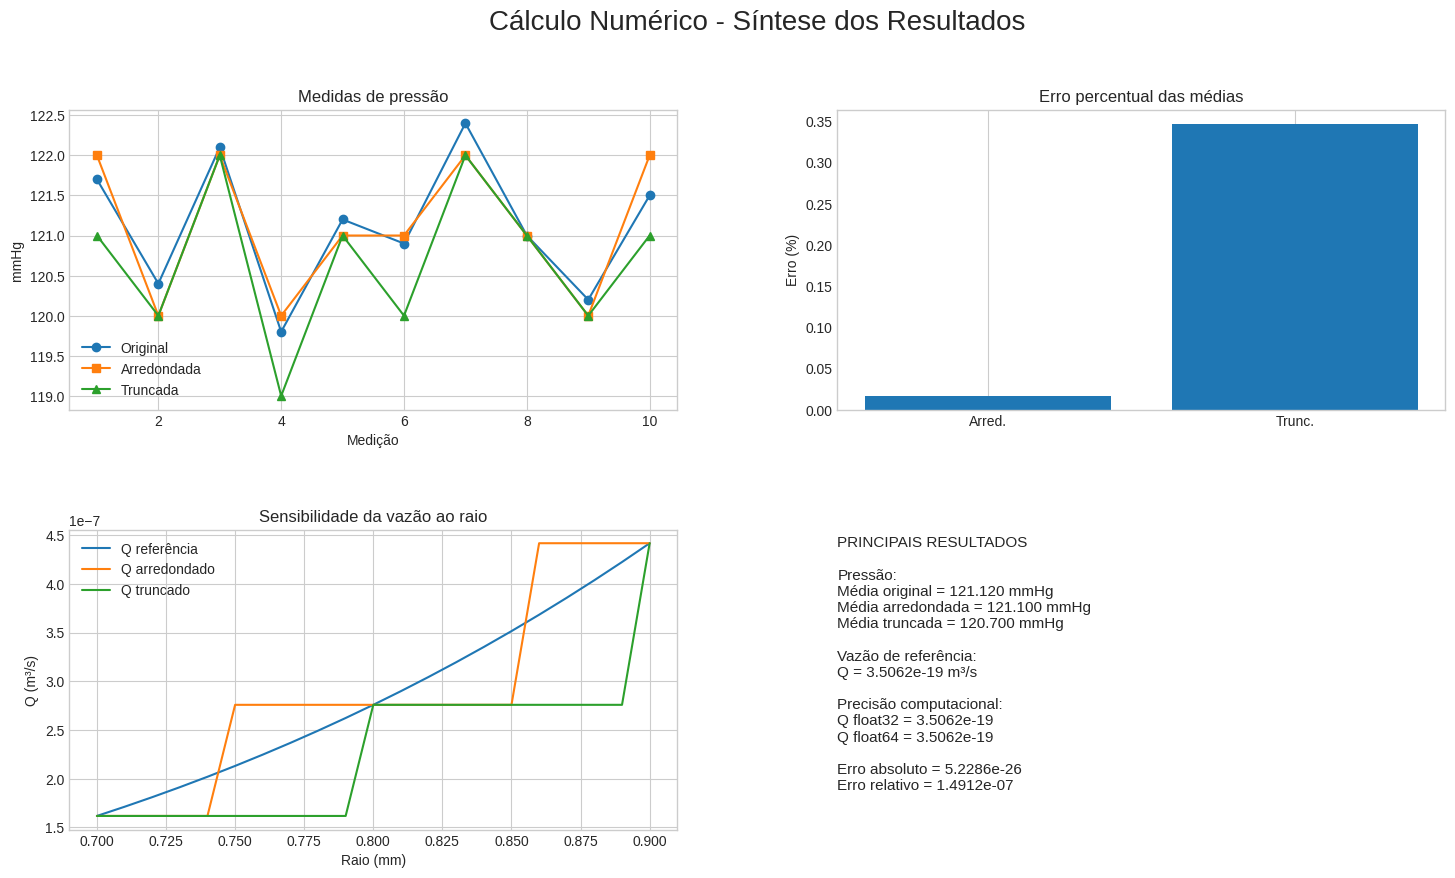

In [10]:


# ==========================================================
# QUADRO ÚNICO DE RESULTADOS
# ==========================================================

fig = plt.figure(
    figsize=(16, 10),
    dpi=100
)


# ==========================================================
# TÍTULO
# ==========================================================

fig.suptitle(
    "Cálculo Numérico - Síntese dos Resultados",
    fontsize=20
)


# ==========================================================
# PAINEL 1 - PRESSÃO
# ==========================================================

ax1 = fig.add_axes(
    [0.07, 0.58, 0.38, 0.30]
)

medicoes = range(
    1,
    len(p) + 1
)

ax1.plot(
    medicoes,
    p,
    marker="o",
    label="Original"
)

ax1.plot(
    medicoes,
    a,
    marker="s",
    label="Arredondada"
)

ax1.plot(
    medicoes,
    t,
    marker="^",
    label="Truncada"
)

ax1.set_title(
    "Medidas de pressão"
)

ax1.set_xlabel(
    "Medição"
)

ax1.set_ylabel(
    "mmHg"
)

ax1.grid(True)
ax1.legend()


# ==========================================================
# PAINEL 2 - ERROS DAS MÉDIAS
# ==========================================================

ax2 = fig.add_axes(
    [0.55, 0.58, 0.38, 0.30]
)

ax2.bar(
    [
        "Arred.",
        "Trunc."
    ],
    [
        Eperc_a,
        Eperc_t
    ]
)

ax2.set_title(
    "Erro percentual das médias"
)

ax2.set_ylabel(
    "Erro (%)"
)

ax2.grid(
    axis="y"
)


# ==========================================================
# PAINEL 3 - SENSIBILIDADE Q x r
# ==========================================================

ax3 = fig.add_axes(
    [0.07, 0.16, 0.38, 0.30]
)

ax3.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Q referência"],
    label="Q referência"
)

ax3.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Q arredondado"],
    label="Q arredondado"
)

ax3.plot(
    tabela_C2["r (mm)"],
    tabela_C2["Q truncado"],
    label="Q truncado"
)

ax3.set_title(
    "Sensibilidade da vazão ao raio"
)

ax3.set_xlabel(
    "Raio (mm)"
)

ax3.set_ylabel(
    "Q (m³/s)"
)

ax3.grid(True)
ax3.legend()


# ==========================================================
# PAINEL 4 - TEXTO DOS PRINCIPAIS RESULTADOS
# ==========================================================

ax4 = fig.add_axes(
    [0.55, 0.13, 0.38, 0.34]
)

ax4.axis(
    "off"
)


texto = f"""
PRINCIPAIS RESULTADOS

Pressão:
Média original = {media:.3f} mmHg
Média arredondada = {mediaa:.3f} mmHg
Média truncada = {mediat:.3f} mmHg

Vazão de referência:
Q = {Q_ref:.4e} m³/s

Precisão computacional:
Q float32 = {Q32:.4e}
Q float64 = {Q64:.4e}

Erro absoluto = {diferenca_absoluta:.4e}
Erro relativo = {diferenca_relativa:.4e}
"""


ax4.text(
    0,
    1,
    texto,
    va="top",
    fontsize=11
)


# ==========================================================
# SALVAR
# ==========================================================

plt.savefig(
    "quadro_resultados.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

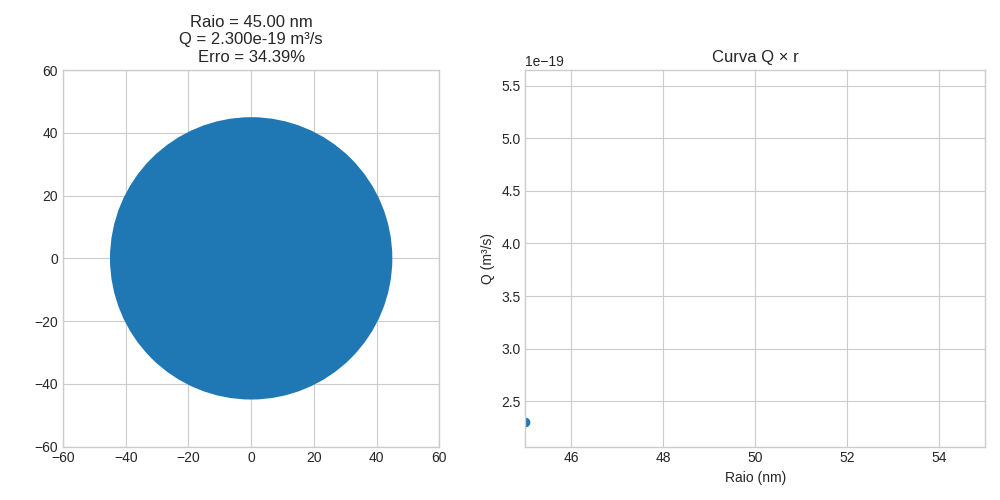

In [11]:
from matplotlib.animation import FuncAnimation
from IPython.display import Image, display


# ==========================================================
# FUNÇÃO DE VAZÃO
# ==========================================================

def vazao(r, delta_p, mu, L):

    return (
        math.pi
        * r**4
        * delta_p
        / (8 * mu * L)
    )


# ==========================================================
# VALORES DO NANOCATETER
# ==========================================================

r_ref_nm = 50

r_ref = (
    r_ref_nm * 1e-9
)

L = 10e-6

mu = 3.5e-3

delta_p = 5000


Q_ref = vazao(
    r_ref,
    delta_p,
    mu,
    L
)


# ==========================================================
# 50 QUADROS ENTRE 45 E 55 nm
# ==========================================================

raios_nm = np.linspace(
    45,
    55,
    50
)


Q_valores = []


for r_nm in raios_nm:

    r = r_nm * 1e-9

    Q_valores.append(
        vazao(
            r,
            delta_p,
            mu,
            L
        )
    )


# ==========================================================
# FIGURA
# ==========================================================

fig = plt.figure(
    figsize=(10, 5)
)


# ==========================================================
# FUNÇÃO DE ATUALIZAÇÃO
# ==========================================================

def atualizar(frame):

    plt.clf()


    r_nm = raios_nm[frame]

    Q_atual = Q_valores[frame]


    erro_percentual = (
        abs(Q_atual - Q_ref)
        / abs(Q_ref)
        * 100
    )


    # ------------------------------------------------------
    # SEÇÃO TRANSVERSAL
    # ------------------------------------------------------

    ax1 = plt.subplot(
        1,
        2,
        1
    )


    circulo = plt.Circle(
        (0, 0),
        r_nm
    )


    ax1.add_patch(
        circulo
    )


    ax1.set_xlim(
        -60,
        60
    )

    ax1.set_ylim(
        -60,
        60
    )

    ax1.set_aspect(
        "equal"
    )


    ax1.set_title(
        f"Raio = {r_nm:.2f} nm\n"
        f"Q = {Q_atual:.3e} m³/s\n"
        f"Erro = {erro_percentual:.2f}%"
    )


    # ------------------------------------------------------
    # CURVA Q x r
    # ------------------------------------------------------

    ax2 = plt.subplot(
        1,
        2,
        2
    )


    ax2.plot(
        raios_nm[:frame + 1],
        Q_valores[:frame + 1],
        marker="o"
    )


    ax2.set_xlim(
        45,
        55
    )


    ax2.set_ylim(
        min(Q_valores) * 0.9,
        max(Q_valores) * 1.1
    )


    ax2.set_xlabel(
        "Raio (nm)"
    )

    ax2.set_ylabel(
        "Q (m³/s)"
    )


    ax2.set_title(
        "Curva Q × r"
    )


    ax2.grid(True)


    plt.tight_layout()


# ==========================================================
# CRIAÇÃO DO GIF
# ==========================================================

animacao = FuncAnimation(

    fig,

    atualizar,

    frames=len(raios_nm),

    interval=150
)


# ==========================================================
# SALVAR GIF
# ==========================================================

animacao.save(
    "nanocateter.gif",
    writer="pillow",
    fps=8
)


plt.close()


# ==========================================================
# MOSTRAR GIF NO COLAB
# ==========================================================

display(
    Image(
        filename="nanocateter.gif"
    )
)